## Import Libraries

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

## Load Dataset

In [36]:
prepared_data = joblib.load(
    "../data/processed/prepared_data.pkl"
)

X_train = prepared_data["X_train"]
X_test = prepared_data["X_test"]
y_train = prepared_data["y_train"]
y_test = prepared_data["y_test"]

best_log_model = joblib.load(
    "../models/best_churn_model.pkl"
)

## Feature Importance Analysis

In [37]:

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": best_log_model.coef_[0]
})

feature_importance["Absolute Importance"] = np.abs(
    feature_importance["Coefficient"]
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Coefficient,Absolute Importance
25,Contract_Two year,-1.186609,1.186609
1,tenure,-1.010534,1.010534
10,InternetService_Fiber optic,0.656652,0.656652
24,Contract_One year,-0.632989,0.632989
13,OnlineSecurity_Yes,-0.434838,0.434838
28,PaymentMethod_Electronic check,0.392874,0.392874
19,TechSupport_Yes,-0.380578,0.380578
26,PaperlessBilling_Yes,0.331737,0.331737
3,TotalCharges,0.296169,0.296169
7,PhoneService_Yes,-0.285696,0.285696


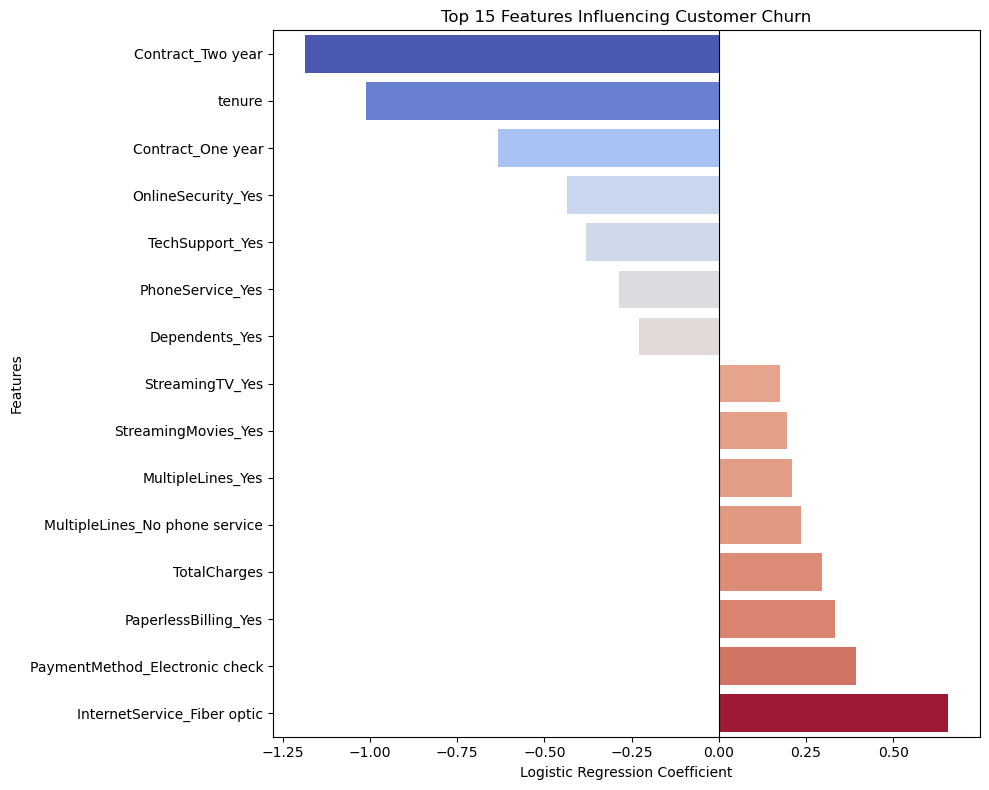

In [38]:
# Visualize feature importance analysis

top_features = feature_importance.head(15).sort_values(
    by="Coefficient"
)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature",
    hue="Coefficient",
    palette="coolwarm",
    legend=False
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title("Top 15 Features Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Features")

plt.tight_layout()

plt.show()

### Feature Importance Analysis

Feature importance analysis was performed using the coefficients of the optimized Logistic Regression model to identify the factors most strongly associated with customer churn predictions.

The results revealed that contract type and customer tenure were among the most influential features. Customers with two-year contracts and longer tenure had strong negative coefficients, indicating a lower tendency towards churn predictions.

On the other hand, fiber optic internet service, electronic check payment method, paperless billing, and total charges had positive coefficients, indicating a higher tendency towards churn predictions.

Overall, the analysis suggests that contract type, customer tenure, internet service type, payment method, and additional services are important factors in predicting customer churn.

## Individual Prediction Interpretation

In [39]:
# Generate individual customer predictions

y_pred = best_log_model.predict(X_test)

# Calculate individual churn probabilities

y_prob = best_log_model.predict_proba(X_test)[:, 1]

The optimized Logistic Regression model was used to generate individual customer churn predictions and estimate the probability of churn for each customer in the test dataset.

The model produced binary predictions, where 0 represents customers predicted not to churn and 1 represents customers predicted to churn. It also generated individual churn probabilities, indicating the estimated likelihood of each customer leaving the company.

This provides a foundation for examining how the model makes predictions at the individual customer level.

In [40]:
# Create the individual prediction results table

prediction_results = pd.DataFrame({
    "Actual Churn": y_test.values,
    "Predicted Churn": y_pred,
    "Churn Probability": y_prob
})

prediction_results.head(10)

,Actual Churn,Predicted Churn,Churn Probability
0,0,0,0.114245
1,0,1,0.851339
2,0,0,0.168862
3,0,1,0.644895
4,0,0,0.067692
5,0,1,0.802133
6,0,1,0.695621
7,0,0,0.283250
8,0,0,0.013112
9,1,1,0.658463


A prediction results table was created by combining the actual churn status, predicted churn status, and predicted churn probability for each customer.

The table allows for a direct comparison between actual customer behaviour and the model's predictions. It also provides insight into the estimated likelihood of churn for individual customers.

For example, some customers received high predicted churn probabilities despite not actually churning, while others received low probabilities and were correctly classified as non-churners.

In [41]:
# Classify prediction outcomes

prediction_results["Prediction Outcome"] = np.select(
    [
        (prediction_results["Actual Churn"] == 1) &
        (prediction_results["Predicted Churn"] == 1),

        (prediction_results["Actual Churn"] == 0) &
        (prediction_results["Predicted Churn"] == 0),

        (prediction_results["Actual Churn"] == 0) &
        (prediction_results["Predicted Churn"] == 1),

        (prediction_results["Actual Churn"] == 1) &
        (prediction_results["Predicted Churn"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ]
)

prediction_results.head(10)

,Actual Churn,Predicted Churn,Churn Probability,Prediction Outcome
0,0,0,0.114245,True Negative
1,0,1,0.851339,False Positive
2,0,0,0.168862,True Negative
3,0,1,0.644895,False Positive
4,0,0,0.067692,True Negative
5,0,1,0.802133,False Positive
6,0,1,0.695621,False Positive
7,0,0,0.283250,True Negative
8,0,0,0.013112,True Negative
9,1,1,0.658463,True Positive


Individual predictions were classified into four categories: True Positive, True Negative, False Positive, and False Negative.

True Positives represent customers correctly predicted to churn, while True Negatives represent customers correctly predicted not to churn. False Positives represent customers incorrectly predicted to churn, whereas False Negatives represent actual churners that the model failed to identify.

This classification provides a clearer understanding of the model's correct predictions and classification errors at the individual customer level.

In [42]:
# Count prediction outcomes

prediction_results["Prediction Outcome"].value_counts()

Prediction Outcome
True Negative     754
True Positive     293
False Positive    281
False Negative     81
Name: count, dtype: int64

The prediction outcomes were examined across the entire test dataset of 1,409 customers.

The results showed 754 True Negatives, 293 True Positives, 281 False Positives, and 81 False Negatives.

The model correctly classified 1,047 customers, while 362 customers were incorrectly classified. These findings provide an overview of the model's prediction performance and demonstrate its ability to identify both churning and non-churning customers.

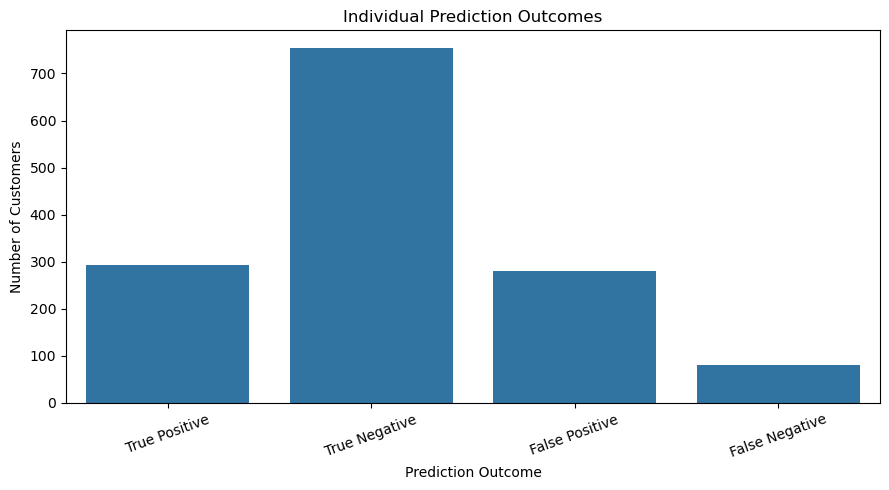

In [43]:
# Visualize prediction outcomes

plt.figure(figsize=(9, 5))

sns.countplot(
    data=prediction_results,
    x="Prediction Outcome",
    order=[
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ]
)

plt.title("Individual Prediction Outcomes")
plt.xlabel("Prediction Outcome")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

A bar chart was created to visualize the distribution of the four prediction outcomes across the test dataset.

The visualization shows that True Negatives had the highest count, followed by True Positives, False Positives, and False Negatives.

This provides a clear visual comparison of the model's correct classifications and prediction errors, making its performance easier to understand and communicate.

In [44]:
# Identify the 10 customers with the highest churn probabilities

high_risk_customers = prediction_results.sort_values(
    by="Churn Probability",
    ascending=False
)

high_risk_customers.head(10)

,Actual Churn,Predicted Churn,Churn Probability,Prediction Outcome
1090,1,1,0.939040,True Positive
1221,1,1,0.928872,True Positive
1164,1,1,0.926433,True Positive
1175,1,1,0.925136,True Positive
1138,1,1,0.924394,True Positive
627,1,1,0.923345,True Positive
647,1,1,0.922523,True Positive
1109,1,1,0.922045,True Positive
889,0,1,0.919618,False Positive
995,0,1,0.916390,False Positive


The ten customers with the highest predicted churn probabilities were identified using the optimized Logistic Regression model.

The results showed that eight customers were correctly predicted to churn, while two were incorrectly classified as potential churners. Their predicted churn probabilities ranged from approximately 91.64% to 93.90%.

These findings demonstrate how the model can identify customers with a high estimated likelihood of churn. Such predictions can help the telecom company prioritize potentially at-risk customers and develop targeted retention strategies.

### Summary of Individual Prediction Interpretation

Individual prediction interpretation was performed to understand how the optimized Logistic Regression model generates churn predictions for individual customers.

The analysis examined actual and predicted churn statuses, estimated churn probabilities, classification outcomes, and customers with the highest predicted churn risks.

The results demonstrated that the model could correctly identify a substantial number of customers who churned and those who remained with the company. The identification of high-risk customers also highlighted the potential application of the model in supporting customer retention decisions.

Overall, the analysis provides insight into the model's individual predictions and demonstrates how its outputs can support data-driven customer retention strategies.

## Business Recommendations

Based on the findings from the feature importance analysis and individual prediction interpretation, the following business recommendations are proposed to help reduce customer churn:

1. **Encourage Long-Term Contracts:** The company should introduce incentives and attractive subscription packages to encourage customers to adopt longer-term contracts, as contract type was identified as an important factor associated with churn predictions.

2. **Improve New Customer Retention:** Additional attention should be given to customers with shorter tenure through effective onboarding programmes, regular communication, and improved customer support.

3. **Investigate Fibre-Optic Service Satisfaction:** The company should examine service quality, pricing, and customer satisfaction among fibre-optic subscribers to understand their association with higher churn predictions.

4. **Improve Payment Experience:** The company should investigate potential payment-related challenges associated with electronic check usage and promote convenient payment alternatives.

5. **Implement Targeted Retention Strategies:** Customers identified with high predicted churn probabilities should receive priority attention through personalized retention campaigns, loyalty incentives, and proactive customer support.

Overall, these recommendations demonstrate how machine learning predictions and feature importance findings can support informed business decisions, improve customer retention strategies, and potentially reduce customer churn.

## Model Limitations

Despite the satisfactory performance of the optimized Logistic Regression model, certain limitations should be considered when interpreting its predictions.

1. **Prediction Errors:** The model produced 281 False Positives and 81 False Negatives, indicating that some customers were incorrectly classified. These errors may affect the effectiveness of customer retention decisions.

2. **Limited Dataset Features:** The model relies on the features available in the dataset. Important factors such as customer satisfaction, competitor activities, and individual customer circumstances may not be adequately represented.

3. **Changing Customer Behaviour:** Customer preferences and behaviour may change over time. Therefore, patterns learned from historical data may not always reflect future customer behaviour.

4. **Model Assumptions:** Logistic Regression assumes a linear relationship between the input features and the log-odds of the outcome. As a result, complex relationships between customer characteristics and churn may not be fully captured.

5. **Probability Limitations:** The predicted churn probabilities represent estimated likelihoods rather than guaranteed outcomes. Their reliability depends partly on the calibration and generalization ability of the model.

Overall, these limitations highlight the importance of continuous model monitoring, periodic retraining, improved data collection, and careful interpretation of prediction results.